<a href="https://colab.research.google.com/github/diinchik/NeuralNetwork/blob/main/Lab3_NeuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

print("Версія TensorFlow:", tf.__version__)
print("Бібліотеки підключено успішно!")

Версія TensorFlow: 2.21.0
Бібліотеки підключено успішно!


In [2]:
# Завантаження набору даних MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Виведення інформації про набір даних
print("Навчальних зображень:", x_train.shape[0])
print("Тестових зображень:", x_test.shape[0])
print("Розмір зображення:", x_train.shape[1], "x", x_train.shape[2], "пікселів")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Навчальних зображень: 60000
Тестових зображень: 10000
Розмір зображення: 28 x 28 пікселів


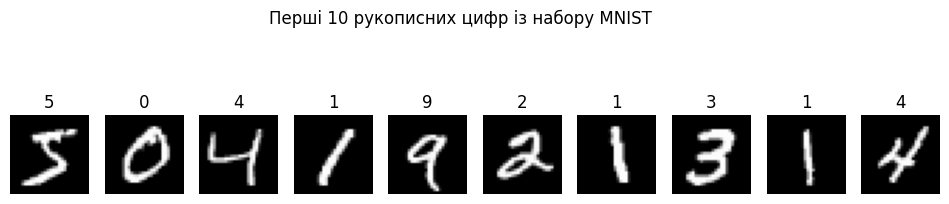

In [3]:
# Відображення перших 10 зображень MNIST
plt.figure(figsize=(12, 3))

for i in range(10):
    plt.subplot(1, 10, i + 1)

    # Відображення рукописної цифри
    plt.imshow(x_train[i], cmap='gray')

    # Правильна відповідь для зображення
    plt.title(str(y_train[i]))

    plt.axis('off')

plt.suptitle("Перші 10 рукописних цифр із набору MNIST")
plt.show()

In [4]:
# Нормалізація навчальних і тестових даних
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Перевірка результату нормалізації
print("Нормалізацію завершено!")
print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())
print("Форма навчальних даних:", x_train.shape)
print("Форма тестових даних:", x_test.shape)

Нормалізацію завершено!
Мінімальне значення: 0.0
Максимальне значення: 1.0
Форма навчальних даних: (60000, 28, 28)
Форма тестових даних: (10000, 28, 28)


In [5]:
# Створення нейронної мережі
model = keras.Sequential([
    # Вхідний шар: перетворення 28x28 у 784 значення
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),

    # Прихований шар: 128 нейронів
    keras.layers.Dense(128, activation='relu'),

    # Вихідний шар: 10 нейронів для цифр 0-9
    keras.layers.Dense(10, activation='softmax')
])

# Виведення структури нейронної мережі
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Налаштування нейронної мережі
model.compile(
    optimizer='adam',  # Алгоритм оптимізації ваг
    loss='sparse_categorical_crossentropy',  # Функція втрат
    metrics=['accuracy']  # Метрика точності
)

print("Модель готова до навчання!")

# Навчання нейронної мережі
history = model.fit(
    x_train,
    y_train,
    epochs=5,  # Кількість епох навчання
    batch_size=32,  # Кількість зображень в одному пакеті
    validation_split=0.1  # 10% даних для валідації
)

print("Навчання нейронної мережі завершено!")

Модель готова до навчання!
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9211 - loss: 0.2746 - val_accuracy: 0.9627 - val_loss: 0.1294
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9650 - loss: 0.1178 - val_accuracy: 0.9748 - val_loss: 0.0910
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9758 - loss: 0.0799 - val_accuracy: 0.9763 - val_loss: 0.0807
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9821 - loss: 0.0584 - val_accuracy: 0.9782 - val_loss: 0.0755
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9859 - loss: 0.0460 - val_accuracy: 0.9757 - val_loss: 0.0845
Навчання нейронної мережі завершено!


In [7]:
# Оцінювання нейронної мережі на тестових даних
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

# Виведення результатів
print("=== РЕЗУЛЬТАТИ ТЕСТУВАННЯ ===")
print(f"Точність на тестових даних: {test_accuracy * 100:.2f}%")
print(f"Помилка (loss): {test_loss:.4f}")

=== РЕЗУЛЬТАТИ ТЕСТУВАННЯ ===
Точність на тестових даних: 97.50%
Помилка (loss): 0.0790


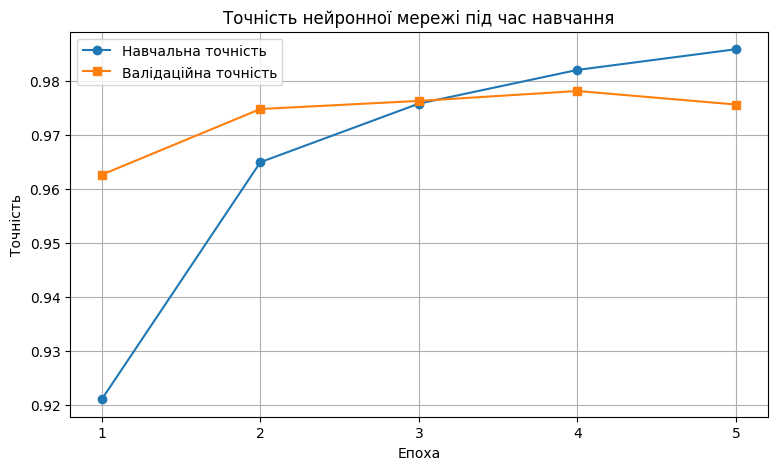

In [8]:
# Побудова графіка точності нейронної мережі
plt.figure(figsize=(9, 5))

# Точність на навчальних даних
plt.plot(
    history.history['accuracy'],
    marker='o',
    label='Навчальна точність'
)

# Точність на валідаційних даних
plt.plot(
    history.history['val_accuracy'],
    marker='s',
    label='Валідаційна точність'
)

plt.title('Точність нейронної мережі під час навчання')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.xticks(range(5), range(1, 6))
plt.legend()
plt.grid(True)

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


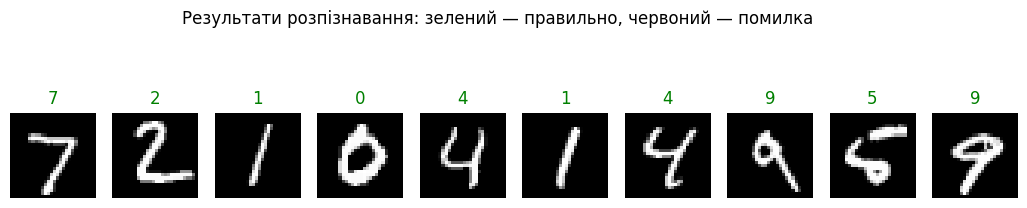

Зображення 1: Прогноз = 7, Правильна цифра = 7
Зображення 2: Прогноз = 2, Правильна цифра = 2
Зображення 3: Прогноз = 1, Правильна цифра = 1
Зображення 4: Прогноз = 0, Правильна цифра = 0
Зображення 5: Прогноз = 4, Правильна цифра = 4
Зображення 6: Прогноз = 1, Правильна цифра = 1
Зображення 7: Прогноз = 4, Правильна цифра = 4
Зображення 8: Прогноз = 9, Правильна цифра = 9
Зображення 9: Прогноз = 5, Правильна цифра = 5
Зображення 10: Прогноз = 9, Правильна цифра = 9


In [9]:
# Отримання прогнозів для перших 10 тестових зображень
predictions = model.predict(x_test[:10])

# Створення графіка з результатами розпізнавання
plt.figure(figsize=(13, 3))

for i in range(10):
    plt.subplot(1, 10, i + 1)

    # Відображення зображення цифри
    plt.imshow(x_test[i], cmap='gray')

    # Прогноз нейронної мережі
    predicted = np.argmax(predictions[i])

    # Правильна відповідь
    correct = y_test[i]

    # Зелений — правильно, червоний — помилка
    color = 'green' if predicted == correct else 'red'

    plt.title(f"{predicted}", color=color)
    plt.axis('off')

plt.suptitle(
    "Результати розпізнавання: зелений — правильно, червоний — помилка"
)

plt.show()

# Виведення результатів у консоль
for i in range(10):
    predicted = np.argmax(predictions[i])
    print(
        f"Зображення {i + 1}: "
        f"Прогноз = {predicted}, "
        f"Правильна цифра = {y_test[i]}"
    )

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Кількість помилкових прогнозів: 250


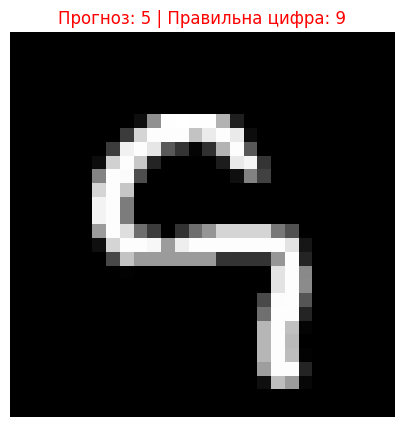

Індекс зображення: 104
Прогноз нейронної мережі: 5
Правильна відповідь: 9


In [10]:
# Отримуємо прогнози для всієї тестової вибірки
predictions_all = model.predict(x_test)

# Визначаємо передбачені цифри
predicted_labels = np.argmax(predictions_all, axis=1)

# Знаходимо індекси помилкових прогнозів
errors = np.where(predicted_labels != y_test)[0]

print("Кількість помилкових прогнозів:", len(errors))

# Відображаємо першу знайдену помилку
if len(errors) > 0:
    i = errors[0]

    plt.figure(figsize=(5, 5))
    plt.imshow(x_test[i], cmap='gray')

    plt.title(
        f"Прогноз: {predicted_labels[i]} | "
        f"Правильна цифра: {y_test[i]}",
        color='red'
    )

    plt.axis('off')
    plt.show()

    print("Індекс зображення:", i)
    print("Прогноз нейронної мережі:", predicted_labels[i])
    print("Правильна відповідь:", y_test[i])
else:
    print("Помилкових прогнозів не знайдено.")

In [11]:
# Функція створення нейронної мережі
def create_model(hidden_layers):
    new_model = keras.Sequential([
        keras.Input(shape=(28, 28)),
        keras.layers.Flatten()
    ])

    # Додаємо приховані шари
    for neurons in hidden_layers:
        new_model.add(
            keras.layers.Dense(neurons, activation='relu')
        )

    # Вихідний шар
    new_model.add(
        keras.layers.Dense(10, activation='softmax')
    )

    new_model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return new_model


# Зберігаємо результати базової моделі
results = {
    "128 нейронів, 5 епох": test_accuracy
}

# Конфігурації для порівняння
experiments = [
    ("64 нейрони, 5 епох", [64], 5),
    ("128 нейронів, 10 епох", [128], 10),
    ("128+64 нейрони, 5 епох", [128, 64], 5)
]

# Навчання та тестування моделей
for name, layers, epochs in experiments:
    print(f"\n=== Навчання: {name} ===")

    new_model = create_model(layers)

    new_model.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=32,
        validation_split=0.1,
        verbose=1
    )

    loss, accuracy = new_model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    results[name] = accuracy

    print(f"Точність моделі: {accuracy * 100:.2f}%")


# Порівняння результатів
print("\n=== ПОРІВНЯННЯ МОДЕЛЕЙ ===")

for name, accuracy in results.items():
    print(f"{name}: {accuracy * 100:.2f}%")


=== Навчання: 64 нейрони, 5 епох ===
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9120 - loss: 0.3118 - val_accuracy: 0.9572 - val_loss: 0.1522
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9557 - loss: 0.1531 - val_accuracy: 0.9667 - val_loss: 0.1122
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9673 - loss: 0.1122 - val_accuracy: 0.9705 - val_loss: 0.0984
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9741 - loss: 0.0879 - val_accuracy: 0.9707 - val_loss: 0.1002
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9775 - loss: 0.0728 - val_accuracy: 0.9728 - val_loss: 0.0884
Точність моделі: 97.22%

=== Навчання: 128 нейронів, 10 епох ===
Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9214 - loss: 0.2751 - val_accuracy: 0.9670 - val_loss: 0.1211
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9652 - loss: 0.1201 - val_accuracy: 0.9705 - val_loss:

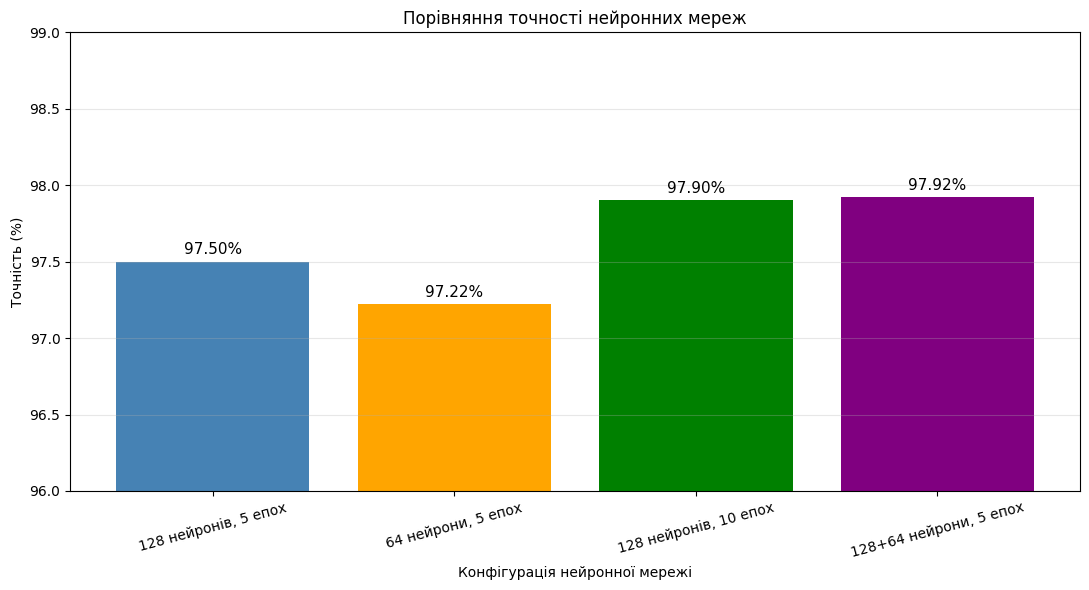

Найкраща модель: 128+64 нейрони, 5 епох
Точність: 97.92%


In [12]:
# Побудова графіка порівняння моделей
names = list(results.keys())
accuracies = [value * 100 for value in results.values()]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    names,
    accuracies,
    color=['steelblue', 'orange', 'green', 'purple']
)

# Відображення точності над стовпчиками
for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'{accuracy:.2f}%',
        ha='center',
        fontsize=11
    )

plt.title('Порівняння точності нейронних мереж')
plt.xlabel('Конфігурація нейронної мережі')
plt.ylabel('Точність (%)')
plt.ylim(96, 99)
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

# Визначення найкращої моделі
best_model = max(results, key=results.get)

print("Найкраща модель:", best_model)
print(f"Точність: {results[best_model] * 100:.2f}%")